# 04 — Model Comparison
**IDX Exchange Data Science Internship — Predicting California Home Close Prices**

Author: Saanvi Prasad

This notebook covers **Week 5** and **Week 6**.

**Week 5 — Additional Models** (sections 1–10)
- Try **Decision Tree** and **Random Forest** regressors
- Compare their **test R²** against the baseline (Linear Regression, R² ≈ 0.68)
- Document how each model behaves (strengths / weaknesses)

**Week 6 — Feature Engineering** (sections 11–16)
- Engineer new features: **bed/bath ratio** and **age of the home**
- Add a **school district** layer by matching each home's coordinates to the CA School District Areas 2024-25 map
- Re-train the models with the new features
- **Deliverable:** table comparing old vs new feature sets, including the school district layer

## Setup

In [7]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

# >>> CHANGE THIS to the folder where your CSV files are (same as in 01, 02 and 03) <<<
path = r"C:\Users\saanv\Desktop\idxexchange"

## 1. Load the train and test data from Week 3
Same files as Week 4, so all models are compared on exactly the same data.
- **Train** = March 2025 – March 2026 (X = 13 months)
- **Test** = April 2026

In [8]:
train = pd.read_csv(os.path.join(path, "train_data.csv"))
test = pd.read_csv(os.path.join(path, "test_data.csv"))

print("Training rows:", len(train), "| months:", train["Month"].min(), "to", train["Month"].max())
print("Test rows:    ", len(test), "| month:", test["Month"].unique()[0])

Training rows: 140798 | months: 2025-03 to 2026-03
Test rows:     12465 | month: 2026-04


## 2. Prepare the data (same as Week 3 and 4)
Same `prepare()` function as before, with **one addition: `Latitude` and `Longitude`** (the map coordinates of each home). Tree models can split on coordinates ("is the home west of longitude −118.4?"), which lets them carve out neighborhoods much more precisely than county and city alone. All three models get the same inputs, including the Linear Regression.

Tree models don't actually *need* scaling or logs of the features, since they only split values into "bigger than" / "smaller than". But keeping the exact same inputs makes the comparison fair: the only thing that changes is the model.

In [9]:
number_cols = ["Latitude", "Longitude", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet",
               "YearBuilt", "GarageSpaces", "Stories"]
flag_cols = ["Latitude", "LotSizeSquareFeet", "YearBuilt", "GarageSpaces", "Stories"]
yes_no_cols = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]


def prepare(train, test, extra_cols=[]):
    """extra_cols = any new number columns to add (used in Week 6)."""
    train = train.copy()
    test = test.copy()
    num_cols = number_cols + extra_cols

    # 1. Missing values
    for col in flag_cols:                          # flag first (before filling)
        train[col + "_missing"] = train[col].isna().astype(int)
        test[col + "_missing"] = test[col].isna().astype(int)
    for col in num_cols:                           # fill with TRAINING median
        median = train[col].median()
        train[col] = train[col].fillna(median)
        test[col] = test[col].fillna(median)
    for col in yes_no_cols:
        train[col] = train[col].fillna(0)
        test[col] = test[col].fillna(0)
    train["City"] = train["City"].fillna("Unknown")
    test["City"] = test["City"].fillna("Unknown")

    # 2. Log of skewed columns
    for d in [train, test]:
        d["LivingArea"] = np.log(d["LivingArea"])
        d["LotSizeSquareFeet"] = np.log(d["LotSizeSquareFeet"])

    # 3. Encoding: keep cities with 100+ training sales, the rest become "Other"
    city_counts = train["City"].value_counts()
    big_cities = city_counts[city_counts >= 100].index
    train["City"] = train["City"].where(train["City"].isin(big_cities), "Other")
    test["City"] = test["City"].where(test["City"].isin(big_cities), "Other")

    feature_cols = num_cols + [c + "_missing" for c in flag_cols] + yes_no_cols + ["CountyOrParish", "City"]
    X_train = pd.get_dummies(train[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = pd.get_dummies(test[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)   # same columns as train

    # 4. Normalize number columns with TRAINING mean and std
    for col in num_cols:
        mean = X_train[col].mean()
        std = X_train[col].std()
        X_train[col] = (X_train[col] - mean) / std
        X_test[col] = (X_test[col] - mean) / std

    y_train = np.log(train["ClosePrice"])
    y_test = np.log(test["ClosePrice"])
    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = prepare(train, test)
actual_price = np.exp(y_test)
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

X_train: (140798, 400)
X_test:  (12465, 400)


## 3. A helper to score each model
Every model predicts **log(price)**, so I turn predictions back into dollars with `np.exp()` and calculate:
- **R² (dollars)**: the official metric
- **R² (log price)**
- **MAE**: average dollar error
- **R² without the top/bottom 0.5% of prices**: same check as Week 4, to see how much the extreme homes matter

In [10]:
low = train["ClosePrice"].quantile(0.005)
high = train["ClosePrice"].quantile(0.995)
middle = (actual_price >= low) & (actual_price <= high)

results = []

def score(name, pred_log, seconds):
    pred_price = np.exp(pred_log)
    results.append({
        "model": name,
        "test R2": r2_score(actual_price, pred_price),
        "test R2 (log)": r2_score(y_test, pred_log),
        "MAE ($)": mean_absolute_error(actual_price, pred_price),
        "R2 w/o top/bottom 0.5%": r2_score(actual_price[middle], pred_price[middle]),
        "train time (s)": seconds,
    })
    print(name, "-> test R²:", round(results[-1]["test R2"], 4))

## 4. Baseline: Linear Regression (from Week 4)
I retrain it here so all the models are in one table.

In [11]:
start = time.time()
lr = LinearRegression()
lr.fit(X_train, y_train)
score("Linear Regression (baseline)", lr.predict(X_test), time.time() - start)

Linear Regression (baseline) -> test R²: 0.6755


## 5. Decision Tree
A decision tree asks a series of yes/no questions (for example "is living area > 2,000 sq ft?" then "is the city Irvine?") and predicts the average price of the homes that end up in the same "leaf".

The most important setting is **`max_depth`**, how many questions deep the tree can go:
- too shallow: the tree is too simple (**underfitting**)
- too deep: the tree memorizes the training data (**overfitting**)

### Choosing max_depth
Like choosing X in Week 3, I **don't** tune on the test month. I train on March 2025 – February 2026 and check each depth on **March 2026** (the validation month).

In [12]:
fit_part = train[train["Month"] < "2026-03"]
val_part = train[train["Month"] == "2026-03"]
X_fit, X_val, y_fit, y_val = prepare(fit_part, val_part)

depth_results = []
for depth in [5, 10, 15, 20, 25, None]:
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=5, random_state=42)
    tree.fit(X_fit, y_fit)
    train_r2 = r2_score(np.exp(y_fit), np.exp(tree.predict(X_fit)))
    val_r2 = r2_score(np.exp(y_val), np.exp(tree.predict(X_val)))
    depth_results.append({"max_depth": str(depth), "train R2": train_r2, "validation R2": val_r2})

depth_results = pd.DataFrame(depth_results)
depth_results

,max_depth,train R2,validation R2
0,5,0.5349,0.5290
1,10,0.7984,0.7425
2,15,0.8818,0.7752
3,20,0.9027,0.7811
4,25,0.9104,0.7849
5,None,0.9172,0.7877


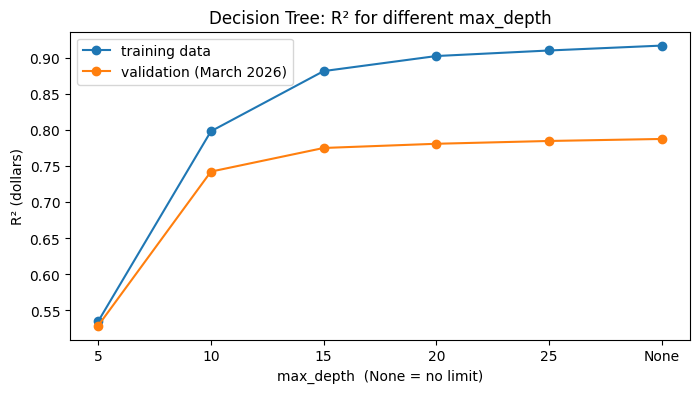

Best max_depth: None


In [13]:
plt.figure(figsize=(8, 4))
plt.plot(depth_results["max_depth"], depth_results["train R2"], marker="o", label="training data")
plt.plot(depth_results["max_depth"], depth_results["validation R2"], marker="o", label="validation (March 2026)")
plt.title("Decision Tree: R² for different max_depth")
plt.xlabel("max_depth  (None = no limit)")
plt.ylabel("R² (dollars)")
plt.legend()
plt.show()

best_depth = depth_results.loc[depth_results["validation R2"].idxmax(), "max_depth"]
best_depth = None if best_depth == "None" else int(best_depth)
print("Best max_depth:", best_depth)

**What I notice:**
- With a shallow tree (depth 5), both training and validation R² are low (~0.53). The tree is too simple (**underfitting**).
- As the tree gets deeper, training R² keeps climbing to about **0.92**, but validation R² levels off around **0.78–0.79**. That growing gap between the two lines is **overfitting**: the tree starts memorizing the training homes.
- Validation R² is highest with no depth limit, so I use `max_depth=None`. `min_samples_leaf=5` still stops it from going all the way down to single homes.

### Train the final Decision Tree and test it on April 2026

In [14]:
start = time.time()
tree = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=5, random_state=42)
tree.fit(X_train, y_train)
score("Decision Tree (max_depth=" + str(best_depth) + ")", tree.predict(X_test), time.time() - start)

Decision Tree (max_depth=None) -> test R²: 0.7467


## 6. Random Forest
A random forest builds **many decision trees** (here 100), each one on a random sample of the homes and a random subset of the columns, and then **averages** their predictions. Averaging many different trees cancels out a lot of their individual mistakes, so a forest usually beats a single tree.

Settings I use:
- `n_estimators=100`: number of trees
- `min_samples_leaf=3`: each leaf needs at least 3 homes (stops trees from memorizing single homes)
- `max_features=0.3`: each split looks at a random 30% of the columns, which makes the trees more different from each other
- `n_jobs=-1`: use all CPU cores so it trains faster

*This cell can take a few minutes.*

In [15]:
start = time.time()
forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.3,
                               n_jobs=-1, random_state=42)
forest.fit(X_train, y_train)
score("Random Forest (100 trees)", forest.predict(X_test), time.time() - start)

Random Forest (100 trees) -> test R²: 0.7412


## 7. Compare the models

In [16]:
results_df = pd.DataFrame(results).set_index("model")
results_df

,test R2,test R2 (log),MAE ($),R2 w/o top/bottom 0.5%,train time (s)
model,,,,,
Linear Regression (baseline),0.6755,0.8676,"262,585.5956",0.7929,4.2882
Decision Tree (max_depth=None),0.7467,0.8816,"239,667.4393",0.7981,4.7198
Random Forest (100 trees),0.7412,0.9154,"207,396.0081",0.8570,31.7421


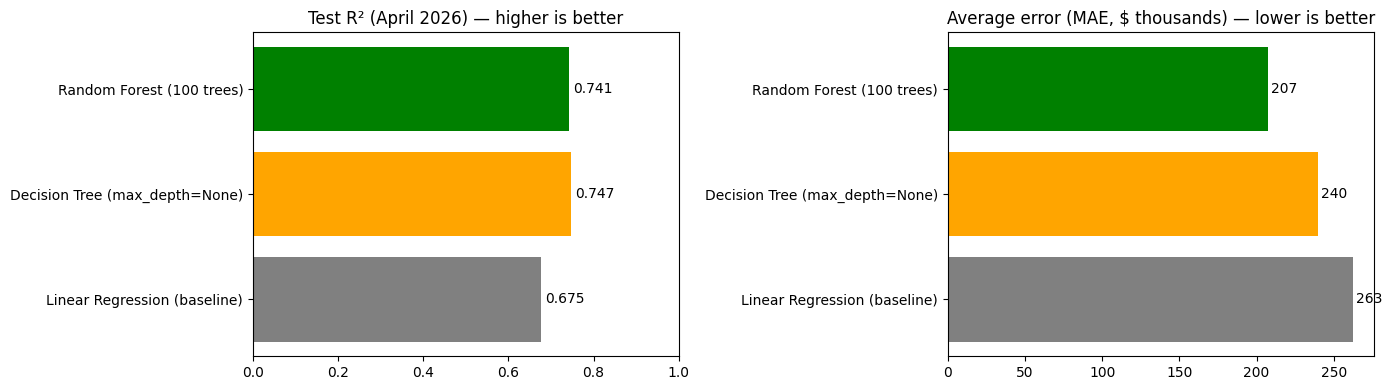

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].barh(results_df.index, results_df["test R2"], color=["gray", "orange", "green"])
axes[0].set_title("Test R² (April 2026) — higher is better")
axes[0].set_xlim(0, 1)
for i, v in enumerate(results_df["test R2"]):
    axes[0].text(v + 0.01, i, round(v, 3), va="center")

axes[1].barh(results_df.index, results_df["MAE ($)"] / 1000, color=["gray", "orange", "green"])
axes[1].set_title("Average error (MAE, $ thousands) — lower is better")
for i, v in enumerate(results_df["MAE ($)"] / 1000):
    axes[1].text(v + 2, i, round(v), va="center")

plt.tight_layout()
plt.show()

**What I notice:**
- **Both tree models beat the baseline.** Test R² goes from **0.68** (Linear Regression) to about **0.75** (Decision Tree) and **0.74** (Random Forest).
- On R² in dollars the Decision Tree and Random Forest are basically **tied**, but the **Random Forest is clearly better on everything else**: lowest average error (**$207K vs $240K vs $263K**), best R² on log price (**0.92**), and best R² once the extreme homes are left out (**0.86**).
- The forest's dollar R² is held back by a few very expensive homes. Averaging 100 trees makes its predictions "play it safe", so it tends to under-predict the most expensive homes, and those errors are huge in dollars.
- Linear Regression is slightly different from Week 4 (0.6755 vs 0.6764) because it now also gets latitude/longitude; for a straight-line model, coordinates barely help.
- The forest takes much longer to train (~1–2 minutes vs a few seconds).

## 8. Predicted vs actual for each model

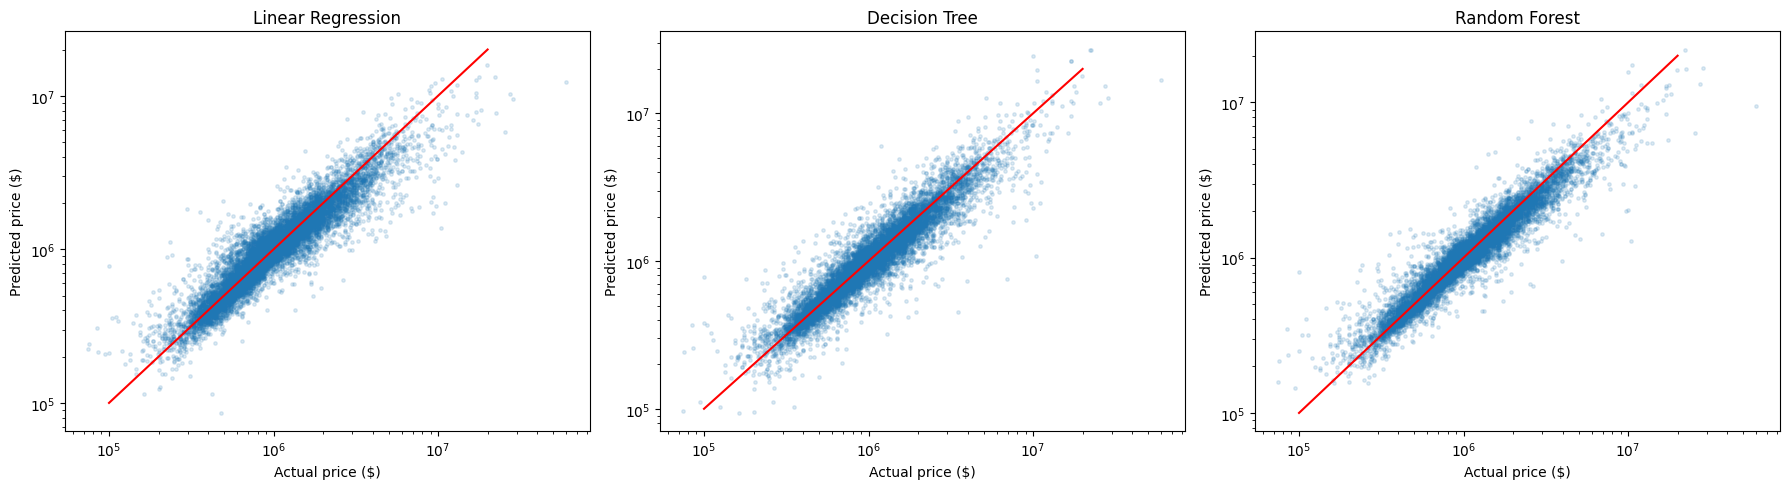

In [18]:
models = {"Linear Regression": lr, "Decision Tree": tree, "Random Forest": forest}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, m) in zip(axes, models.items()):
    pred_price = np.exp(m.predict(X_test))
    ax.scatter(actual_price, pred_price, alpha=0.15, s=6)
    ax.plot([1e5, 2e7], [1e5, 2e7], color="red")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(name)
    ax.set_xlabel("Actual price ($)")
    ax.set_ylabel("Predicted price ($)")
plt.tight_layout()
plt.show()

**What I notice:** all three follow the red line, but the **Random Forest's cloud is the tightest**, meaning its predictions are the most consistent. The Decision Tree's predictions look more "blocky", because every home in the same leaf gets exactly the same price. The Linear Regression cloud is the widest.

## 9. Which features does the Random Forest use most?
Random forests give a **feature importance** score: how much each column helped the trees reduce their error. Higher = more useful.

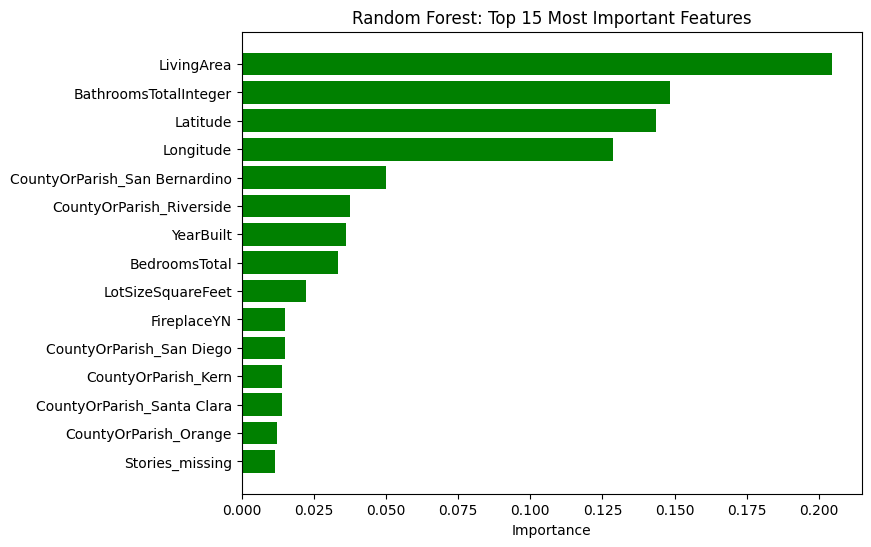

In [19]:
importance = pd.Series(forest.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top15 = importance.head(15)

plt.figure(figsize=(8, 6))
plt.barh(top15.index[::-1], top15.values[::-1], color="green")
plt.title("Random Forest: Top 15 Most Important Features")
plt.xlabel("Importance")
plt.show()

**What I notice:**
- **Living area** is the most important feature, then **bathrooms**.
- **Latitude and longitude** are the 3rd and 4th most important. The forest uses the map coordinates to find expensive and cheap neighborhoods, which is why adding them helped so much.
- Some **county** columns (San Bernardino, Riverside) are also important. These are big, cheaper inland counties, so "is this home in San Bernardino?" is a useful early split.
- This matches Week 2: size and location drive price.

## 10. Save the results

In [20]:
results_df.to_csv(os.path.join(path, "model_comparison_results.csv"))
print("Saved model_comparison_results.csv")

Saved model_comparison_results.csv


---
## Week 5 Summary

| Model | Test R² ($) | Test R² (log) | MAE | Train time |
|---|---|---|---|---|
| Linear Regression (baseline) | 0.68 | 0.87 | ≈ $263K | ~5 s |
| Decision Tree | **0.75** | 0.88 | ≈ $240K | ~7 s |
| Random Forest (100 trees) | 0.74 | **0.92** | **≈ $207K** | ~1–2 min |

### How each model behaves
| Model | Strengths | Weaknesses |
|---|---|---|
| **Linear Regression** | Fast, simple, easy to explain (one coefficient per feature) | Assumes every feature adds the same amount everywhere; can't use map coordinates well |
| **Decision Tree** | Can find neighborhoods and "if this, then that" rules; easy to picture | Overfits easily (training R² 0.92 vs validation 0.79); "blocky" predictions; small data changes can change the whole tree |
| **Random Forest** | Most accurate overall (lowest error, best log R²); averaging many trees reduces overfitting; shows feature importance | Slower to train; harder to explain; tends to under-predict the most expensive homes |

**Takeaways:**
1. Both tree models **beat the baseline** (0.68 → ~0.74–0.75).
2. **Random Forest** is the best model overall: lowest average error and best accuracy on typical homes.
3. **Location detail** (latitude/longitude) matters a lot for tree models.
4. The biggest remaining problem is still the **very expensive homes**, which the Week 6 features below try to improve.

---
# Week 6 — Feature Engineering

## 11. New features: bed/bath ratio and age of the home
- **`BedBathRatio`** = bedrooms ÷ bathrooms. A 4-bed / 1-bath home (ratio 4) is very different from a 4-bed / 4-bath home (ratio 1): more bathrooms per bedroom usually means a nicer, more expensive home.
- **`AgeAtSale`** = year sold − year built. This tells the model how old the home was *when it sold*.

Both are calculated row by row, so they don't use any information from other homes (no leakage).

In [21]:
for d in [train, test]:
    d["BedBathRatio"] = d["BedroomsTotal"] / d["BathroomsTotalInteger"]
    d["AgeAtSale"] = d["Month"].str[:4].astype(int) - d["YearBuilt"]
    d.loc[d["AgeAtSale"] < 0, "AgeAtSale"] = 0          # homes sold before they were finished

train[["BedroomsTotal", "BathroomsTotalInteger", "BedBathRatio", "YearBuilt", "AgeAtSale"]].describe().loc[["mean", "50%", "min", "max"]]

,BedroomsTotal,BathroomsTotalInteger,BedBathRatio,YearBuilt,AgeAtSale
mean,3.4899,2.6269,1.4551,"1,975.8832",49.3154
50%,3.0000,2.0000,1.5000,"1,976.0000",49.0000
min,1.0000,1.0000,0.2500,"1,854.0000",0.0000
max,17.0000,18.0000,7.5000,"2,026.0000",172.0000


**What I notice:** the typical home has a bed/bath ratio of about **1.5** (for example 3 beds / 2 baths) and was about **49 years old** when it sold. Some homes have ratios up to 7.5 (lots of bedrooms but only one bathroom), and the oldest home was 172 years old.

## 12. School district layer
The schedule asks for a more detailed location feature: match each home's **coordinates** to the **school district** it is inside, using the official **CA School District Areas 2024-25** map ([data.ca.gov](https://data.ca.gov/dataset/california-school-district-areas-2024-25)). School districts are a lot smaller than counties, and school quality is a big reason why homes in some areas cost more.

I downloaded the **Shapefile** version (`DistrictAreas2425.zip`) and unzipped it into my project folder, so `DistrictAreas2425.shp` (plus its `.dbf`, `.shx`, `.prj` files) sits next to my CSVs. To read map files I use `geopandas` (install once with `pip install geopandas`).

In [23]:
import geopandas as gpd

districts = gpd.read_file(os.path.join(path, "DistrictAreas2425.zip"))
print("Number of districts:", len(districts))
print("Map coordinate system:", districts.crs)
print(districts["DistrictTy"].value_counts())
districts[["DistrictNa", "DistrictTy", "CountyName"]].head()

Number of districts: 937
Map coordinate system: EPSG:3857
DistrictTy
Elementary    516
Unified       345
High           76
Name: count, dtype: int64


,DistrictNa,DistrictTy,CountyName
0,Alameda Unified,Unified,Alameda
1,Albany City Unified,Unified,Alameda
2,Berkeley Unified,Unified,Alameda
3,Castro Valley Unified,Unified,Alameda
4,Emery Unified,Unified,Alameda


### Matching homes to districts (spatial join)
For each home I make a map point from its longitude/latitude and ask "which district shape is this point inside?". This is called a **spatial join**.

One thing to know: in some parts of California the **elementary** and **high school** districts overlap, so a home can be inside two districts. In that case I keep the **unified or elementary** district (the more local one) and skip the high school one.

In [ ]:
# Put High school districts last, so that when a home is in two districts we keep the more local one
districts["order"] = (districts["DistrictTy"] == "High").astype(int)
districts = districts.sort_values("order")

def add_district(df):
    points = gpd.GeoDataFrame(df[["Longitude", "Latitude"]].copy(),
                              geometry=gpd.points_from_xy(df["Longitude"], df["Latitude"]),
                              crs="EPSG:4326")                 # longitude/latitude
    points = points.to_crs(districts.crs)                       # same map system as the districts
    joined = gpd.sjoin(points, districts[["DistrictNa", "order", "geometry"]], how="left", predicate="within")
    joined = joined.sort_values("order").groupby(level=0).first()   # one district per home
    df = df.copy()
    df["District"] = joined["DistrictNa"].reindex(df.index)
    return df

train = add_district(train)
test = add_district(test)

print("Training homes matched to a district:", round(train["District"].notna().mean() * 100, 2), "%")
print("Test homes matched to a district:    ", round(test["District"].notna().mean() * 100, 2), "%")
print("Different districts in training data:", train["District"].nunique())

Training homes matched to a district: 99.86 %
Test homes matched to a district:     99.33 %
Different districts in training data: 660


### Turning the district into a number: `DistrictPriceLevel`
There are about 1,000 districts, which is too many 0/1 columns. Instead (like a teammate's "city price level" idea) I give each district **one number: its typical price per square foot** in the training data.

- I use the **median of log(price per sq ft)** for each district, using **training homes only** (so nothing from April leaks in).
- Districts with only a few sales are unreliable, so I **blend** each district's median with the overall median: `(count × district median + 20 × overall median) / (count + 20)`. A district with 1,000 sales keeps almost its own value; a district with 3 sales stays close to the overall median.
- Homes in a district not seen in training (or with no coordinates) get the overall median.

In [ ]:
train["log_ppsf"] = np.log(train["ClosePrice"] / train["LivingArea"])
overall_median = train["log_ppsf"].median()

stats = train.groupby("District")["log_ppsf"].agg(["median", "count"])
k = 20
district_level = (stats["count"] * stats["median"] + k * overall_median) / (stats["count"] + k)

for d in [train, test]:
    d["DistrictPriceLevel"] = d["District"].map(district_level).fillna(overall_median)
train = train.drop(columns="log_ppsf")

# Show the most and least expensive districts (with at least 100 sales)
show = pd.DataFrame({"sales": stats["count"], "median $/sqft": np.exp(district_level).round(0)})
show = show[show["sales"] >= 100].sort_values("median $/sqft")
print("Cheapest districts:")
display(show.head(5))
print("Most expensive districts:")
display(show.tail(5))

Cheapest districts:


,sales,median $/sqft
District,,
Mojave Unified,129,218.0000
Barstow Unified,256,224.0000
Helendale Elementary,152,230.0000
Oroville City Elementary,250,230.0000
Konocti Unified,178,230.0000


Most expensive districts:


,sales,median $/sqft
District,,
Laguna Beach Unified,279,"1,460.0000"
Menlo Park City Elementary,110,"1,495.0000"
Cupertino Union,248,"1,536.0000"
Los Altos Elementary,102,"1,568.0000"
Palo Alto Unified,213,"1,756.0000"


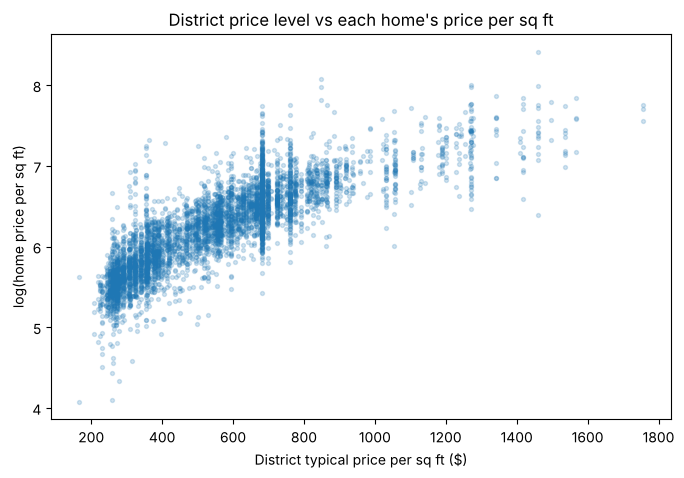

Correlation with log(price per sq ft): 0.848


In [ ]:
# Does the new feature relate to price?
sample = train.sample(5000, random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(np.exp(sample["DistrictPriceLevel"]), np.log(sample["ClosePrice"] / sample["LivingArea"]), alpha=0.2, s=8)
plt.title("District price level vs each home's price per sq ft")
plt.xlabel("District typical price per sq ft ($)")
plt.ylabel("log(home price per sq ft)")
plt.show()
print("Correlation with log(price per sq ft):",
      round(np.corrcoef(train["DistrictPriceLevel"], np.log(train["ClosePrice"] / train["LivingArea"]))[0, 1], 3))

**What I notice:**
- **99.9%** of training homes and **99.3%** of test homes were matched to a school district. The few that weren't have missing or bad coordinates, and they get the overall median.
- The homes fall into **660 different districts**, much more detailed than ~60 counties.
- The cheapest districts (Mojave, Barstow, ~$220/sq ft) are in the desert, and the most expensive (Palo Alto, Los Altos, Cupertino, Laguna Beach, ~$1,500–1,750/sq ft) are in Silicon Valley and coastal Orange County. That's about an **8× difference** in price per square foot.
- `DistrictPriceLevel` has a strong correlation (**0.85**) with each home's price per sq ft, so it should be a useful feature. The tall vertical stripe around $680 is **Los Angeles Unified**, one huge district with very different neighborhoods inside it.

## 13. Re-train the models with the new features
I train all three models on three feature sets, so I can see what each new feature adds:

| Feature set | What's in it |
|---|---|
| **Old (Week 5)** | the same features as sections 1–10 |
| **+ Age & Bed/Bath** | Old + `AgeAtSale` + `BedBathRatio` |
| **+ School district** | Old + `AgeAtSale` + `BedBathRatio` + `DistrictPriceLevel` |

Everything else stays the same: same homes, same train/test months, same model settings (Decision Tree uses the `max_depth` chosen in Week 5). *The Random Forest cells take a few minutes in total.*

In [ ]:
feature_sets = {
    "Old (Week 5)": [],
    "+ Age & Bed/Bath": ["AgeAtSale", "BedBathRatio"],
    "+ School district": ["AgeAtSale", "BedBathRatio", "DistrictPriceLevel"],
}

week6 = []
for set_name, extra in feature_sets.items():
    X_tr, X_te, y_tr, y_te = prepare(train, test, extra_cols=extra)
    models = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=5, random_state=42),
        "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.3,
                                               n_jobs=-1, random_state=42),
    }
    for model_name, m in models.items():
        m.fit(X_tr, y_tr)
        pred_log = m.predict(X_te)
        pred_price = np.exp(pred_log)
        week6.append({
            "feature set": set_name, "model": model_name,
            "test R2": r2_score(actual_price, pred_price),
            "test R2 (log)": r2_score(y_te, pred_log),
            "MAE ($)": mean_absolute_error(actual_price, pred_price),
        })
        print(f"{set_name:20s} {model_name:18s} test R² = {week6[-1]['test R2']:.4f}")
    if set_name == "+ School district":
        final_forest, final_columns = models["Random Forest"], X_tr.columns

week6 = pd.DataFrame(week6)

Old (Week 5)         Linear Regression  test R² = 0.6755


Old (Week 5)         Decision Tree      test R² = 0.7464


Old (Week 5)         Random Forest      test R² = 0.7422


+ Age & Bed/Bath     Linear Regression  test R² = 0.6976


+ Age & Bed/Bath     Decision Tree      test R² = 0.7116


+ Age & Bed/Bath     Random Forest      test R² = 0.7405


+ School district    Linear Regression  test R² = 0.7398


+ School district    Decision Tree      test R² = 0.7206


+ School district    Random Forest      test R² = 0.7620


## 14. Old vs new feature sets (Week 6 deliverable)

In [ ]:
r2_table = week6.pivot(index="model", columns="feature set", values="test R2")[list(feature_sets)]
mae_table = week6.pivot(index="model", columns="feature set", values="MAE ($)")[list(feature_sets)]
r2_table["change (old → district)"] = r2_table["+ School district"] - r2_table["Old (Week 5)"]

print("Test R² (April 2026):")
display(r2_table.round(4))
print("Average error (MAE, $):")
display(mae_table.round(0))

Test R² (April 2026):


feature set,Old (Week 5),+ Age & Bed/Bath,+ School district,change (old → district)
model,,,,
Decision Tree,0.7464,0.7116,0.7206,-0.0257
Linear Regression,0.6755,0.6976,0.7398,0.0643
Random Forest,0.7422,0.7405,0.7620,0.0198


Average error (MAE, $):


feature set,Old (Week 5),+ Age & Bed/Bath,+ School district
model,,,
Decision Tree,"239,588.0000","244,994.0000","247,202.0000"
Linear Regression,"262,586.0000","261,636.0000","252,459.0000"
Random Forest,"206,761.0000","210,991.0000","203,351.0000"


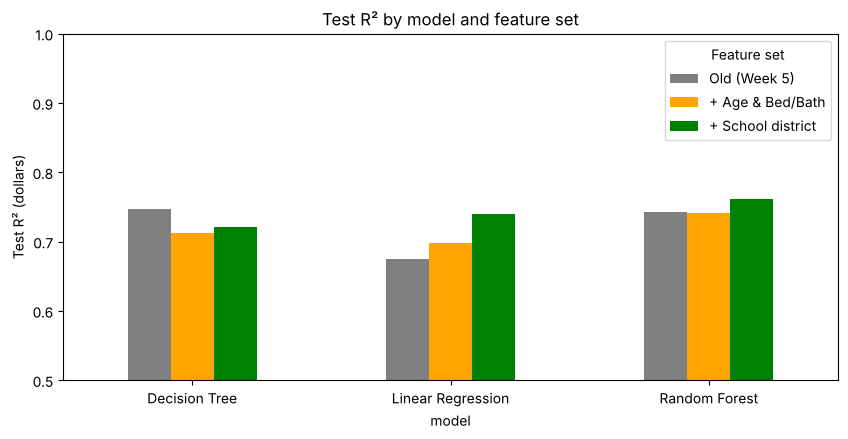

In [ ]:
r2_table[list(feature_sets)].plot(kind="bar", figsize=(10, 4.5), color=["gray", "orange", "green"], rot=0)
plt.title("Test R² by model and feature set")
plt.ylabel("Test R² (dollars)")
plt.ylim(0.5, 1)
plt.legend(title="Feature set")
plt.show()

**What I notice:**
- **Age & Bed/Bath alone barely help.** Linear Regression goes up a little (0.68 → 0.70), but the trees stay about the same or slightly drop. That makes sense: the models already had `YearBuilt`, bedrooms and bathrooms, so age and the ratio are mostly the same information in a new form.
- **The school district layer helps the most.** With `DistrictPriceLevel`:
  - **Linear Regression: 0.68 → 0.74** (+0.06), the biggest jump, because it finally gets a single number that says "how expensive is this area".
  - **Random Forest: 0.74 → 0.76** (+0.02), and its average error drops to about **$203K**, the lowest of any model so far.
  - **Decision Tree: 0.75 → 0.72** (−0.03). A single deep tree is **unstable**: small changes in the features can change its whole structure, so its score jumps around. This is one of the weaknesses from Week 5, and the Random Forest (which averages 100 trees) doesn't have this problem.
- **Best model overall: Random Forest with the school district feature** (R² ≈ 0.76, MAE ≈ $203K).

## 15. Feature importance with the new features (Random Forest)

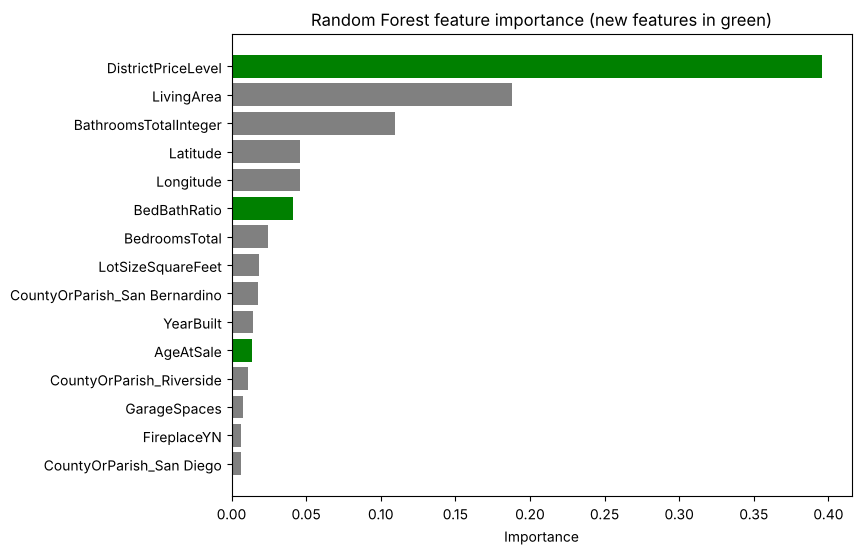

In [ ]:
importance = pd.Series(final_forest.feature_importances_, index=final_columns).sort_values(ascending=False)
top15 = importance.head(15)

plt.figure(figsize=(8, 6))
plt.barh(top15.index[::-1], top15.values[::-1],
         color=["green" if c in ["AgeAtSale", "BedBathRatio", "DistrictPriceLevel"] else "gray" for c in top15.index[::-1]])
plt.title("Random Forest feature importance (new features in green)")
plt.xlabel("Importance")
plt.show()

**What I notice:** `DistrictPriceLevel` is now **by far the most important feature** (about 0.40), more than living area. The forest uses it instead of latitude/longitude and county, which all dropped in importance, because the district number already says how expensive the area is. `BedBathRatio` lands in the top 6, and `AgeAtSale` is about as useful as `YearBuilt` (they hold the same information).

In [ ]:
week6.to_csv(os.path.join(path, "feature_engineering_results.csv"), index=False)
print("Saved feature_engineering_results.csv")

Saved feature_engineering_results.csv


---
## Week 6 Summary

| Model | Old (Week 5) | + Age & Bed/Bath | + School district | Change |
|---|---|---|---|---|
| Linear Regression | 0.68 | 0.70 | **0.74** | +0.06 |
| Decision Tree | 0.75 | 0.71 | 0.72 | −0.03 |
| Random Forest | 0.74 | 0.74 | **0.76** | +0.02 |

*(test R² on April 2026)*

**Takeaways:**
1. **Bed/bath ratio and age** add little, because the models already had bedrooms, bathrooms and year built.
2. The **school district layer** is the most useful new feature. Matching each home to its district and using the district's typical price per sq ft improves Linear Regression and Random Forest, and becomes the Random Forest's #1 feature.
3. The **Random Forest with the school district feature** is the best model so far: R² ≈ 0.76 and the lowest average error (≈ $203K).
4. A single **Decision Tree** is unstable, so its score can go down even when better features are added. Averaging many trees (Random Forest) fixes this.

**Next (Week 7):** try Gradient Boosting (XGBoost or LightGBM) with light tuning, using the new feature set.